In [1]:

from google.colab import files

uploaded = files.upload()


Saving archive (3).zip to archive (3).zip


In [2]:

import os
import zipfile
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Find the uploaded ZIP file automatically
zip_path = next(
    (f for f in uploaded.keys() if f.lower().endswith(".zip")),
    None
)

if zip_path is None:
    raise ValueError("Please upload the stock market ZIP file.")

extract_dir = "/content/stock_data"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully!")
print("CSV files:", len([
    f for f in os.listdir(extract_dir)
    if f.lower().endswith(".csv")
]))


Dataset extracted successfully!
CSV files: 52


Selected stock: RELIANCE
Number of records: 2000
Start date: 2013-03-26
End date: 2021-04-30
Missing values: {'Date': 0, 'Close': 0}


,Date,Close
0,2013-03-26,783.35
1,2013-03-28,772.90
2,2013-04-01,778.75
3,2013-04-02,793.90
4,2013-04-03,776.55


,Date,Close
1995,2021-04-26,1937.85
1996,2021-04-27,1988.65
1997,2021-04-28,1997.30
1998,2021-04-29,2024.05
1999,2021-04-30,1994.50


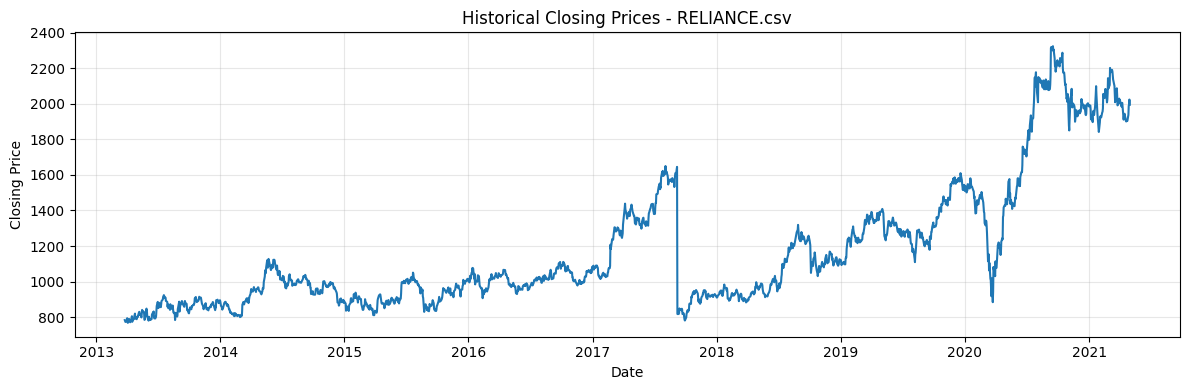

In [3]:

# Select one stock from your uploaded dataset
STOCK_FILE = "RELIANCE.csv"

csv_path = os.path.join(extract_dir, STOCK_FILE)

if not os.path.exists(csv_path):
    available = [
        f for f in os.listdir(extract_dir)
        if f.lower().endswith(".csv")
    ]
    raise FileNotFoundError(
        f"{STOCK_FILE} not found. Available CSV files: {available[:15]}"
    )

df = pd.read_csv(csv_path)

# Standardize column names
df.columns = df.columns.str.strip()

# Validate required columns
if "Date" not in df.columns or "Close" not in df.columns:
    raise ValueError("The CSV must contain Date and Close columns.")

# Convert to appropriate data types
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

# Remove invalid rows and duplicate dates
df = df.dropna(subset=["Date", "Close"])
df = df[df["Close"] > 0]
df = df.sort_values("Date")
df = df.drop_duplicates(subset=["Date"], keep="last")
df = df.reset_index(drop=True)

# Select the latest 2,000 consecutive available trading records
N_RECORDS = 2000

if len(df) < N_RECORDS:
    raise ValueError(
        f"Only {len(df)} valid records available; need {N_RECORDS}."
    )

df = df.tail(N_RECORDS).reset_index(drop=True)

print("Selected stock:", STOCK_FILE.replace(".csv", ""))
print("Number of records:", len(df))
print("Start date:", df["Date"].min().date())
print("End date:", df["Date"].max().date())
print("Missing values:", df[["Date", "Close"]].isna().sum().to_dict())

display(df[["Date", "Close"]].head())
display(df[["Date", "Close"]].tail())

# Plot the selected stock
plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Close"])
plt.title("Historical Closing Prices - " + STOCK_FILE)
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

# Task 1: Normalize closing prices without test-data leakage

LOOKBACK = 60
TRAIN_RATIO = 0.80

prices = df[["Close"]].values.astype("float32")
dates = df["Date"].values

split_idx = int(len(prices) * TRAIN_RATIO)

scaler = MinMaxScaler(feature_range=(0, 1))

# Fit scaler only on training data
scaler.fit(prices[:split_idx])

# Transform all prices using the training-fitted scaler
scaled_prices = scaler.transform(prices)

print("Total records:", len(prices))
print("Training records:", split_idx)
print("Testing records:", len(prices) - split_idx)
print("Lookback window:", LOOKBACK, "trading days")

# Task 2: Create sequences
X_train, y_train = [], []
X_test, y_test = [], []

# Training targets: indices 60 to 1599
for i in range(LOOKBACK, split_idx):
    X_train.append(scaled_prices[i-LOOKBACK:i, 0])
    y_train.append(scaled_prices[i, 0])

# Test targets: indices 1600 to 1999
# Each prediction uses only prices available before its target date.
for i in range(split_idx, len(scaled_prices)):
    X_test.append(scaled_prices[i-LOOKBACK:i, 0])
    y_test.append(scaled_prices[i, 0])

# LSTM expects: samples, time steps, features
X_train = np.array(X_train).reshape(-1, LOOKBACK, 1)
X_test = np.array(X_test).reshape(-1, LOOKBACK, 1)
y_train = np.array(y_train)
y_test = np.array(y_test)

print("\nSequence generation complete!")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


Total records: 2000
Training records: 1600
Testing records: 400
Lookback window: 60 trading days

Sequence generation complete!
X_train shape: (1540, 60, 1)
y_train shape: (1540,)
X_test shape: (400, 60, 1)
y_test shape: (400,)


In [5]:

# Task 3: Build the sequential prediction model

model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(32, return_sequences=False),
    Dropout(0.15),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

model.summary()

# Stop when validation loss no longer improves
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

# Use the last part of training data for validation.
# Do not shuffle time-series sequences.
history = model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=32,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\nModel training completed!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0146 - val_loss: 0.0077 - learning_rate: 0.0010
Epoch 2/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0081 - val_loss: 0.0020 - learning_rate: 0.0010
Epoch 3/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0063 - val_loss: 0.0030 - learning_rate: 0.0010
Epoch 4/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0044 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 5/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0041 - val_loss: 0.0017 - learning_rate: 0.0010
Epoch 6/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0032 - val_loss: 0.0030 - learning_rate: 0.0010
Epoch 7/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0034 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 8/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0035 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 9/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0031 - val_loss: 0.0019 - learning_rate: 5.0000e-04
Epoch 10/40
41/

In [6]:

# Predict on the held-out test set
pred_scaled = model.predict(X_test, verbose=0)

# Convert scaled prices back to original price values
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred_actual = scaler.inverse_transform(
    pred_scaled
).ravel()

# Task 4: Evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("MODEL EVALUATION")
print("-" * 35)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

print("\nInterpretation:")
print(f"On average, absolute prediction error is about {mae:.2f} price units.")
print(f"RMSE penalizes larger errors more heavily: {rmse:.2f} price units.")


MODEL EVALUATION
-----------------------------------
MAE  : 47.0021
RMSE : 60.1528

Interpretation:
On average, absolute prediction error is about 47.00 price units.
RMSE penalizes larger errors more heavily: 60.15 price units.


In [7]:

# Baseline: predict the next close using the previous close

baseline_scaled = scaled_prices[split_idx - 1 : -1]

baseline_pred = scaler.inverse_transform(
    baseline_scaled
).ravel()

baseline_mae = mean_absolute_error(
    y_test_actual, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, baseline_pred)
)

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "LSTM"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse]
})

display(comparison.round(4))

if mae < baseline_mae and rmse < baseline_rmse:
    print("LSTM outperformed the baseline on both metrics.")
else:
    print("LSTM did not outperform the baseline on both metrics.")


,Model,MAE,RMSE
0,Naive Baseline,27.3324,38.5038
1,LSTM,47.0021,60.1528


LSTM did not outperform the baseline on both metrics.


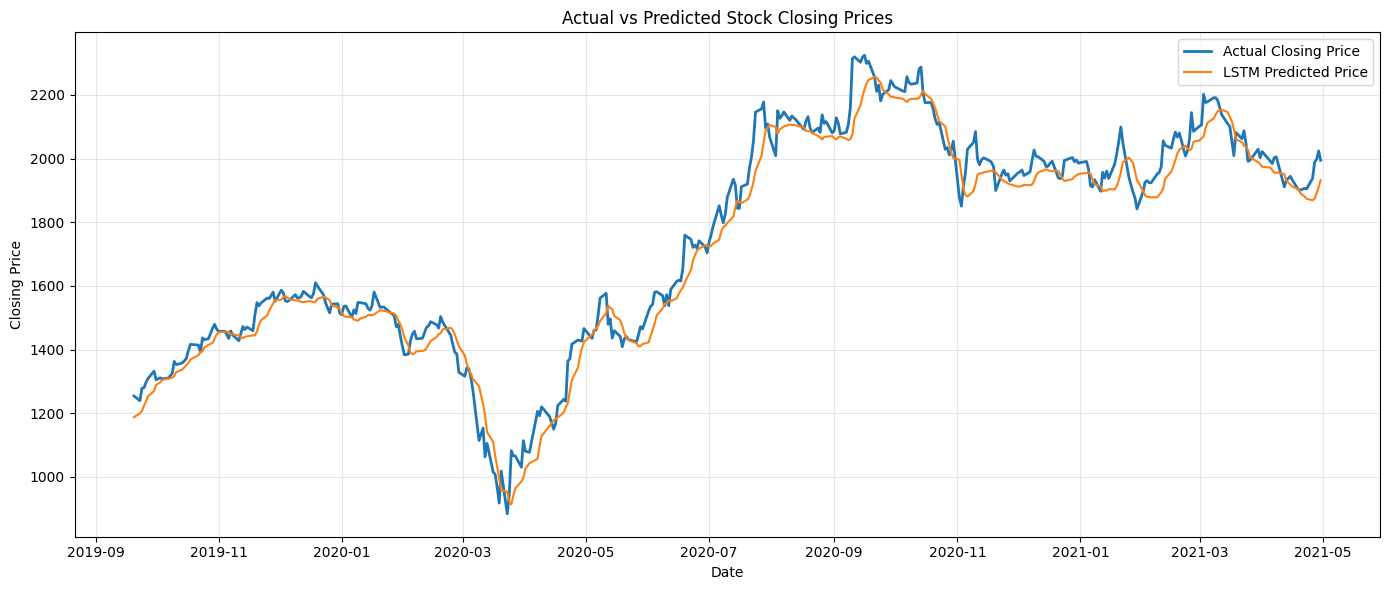

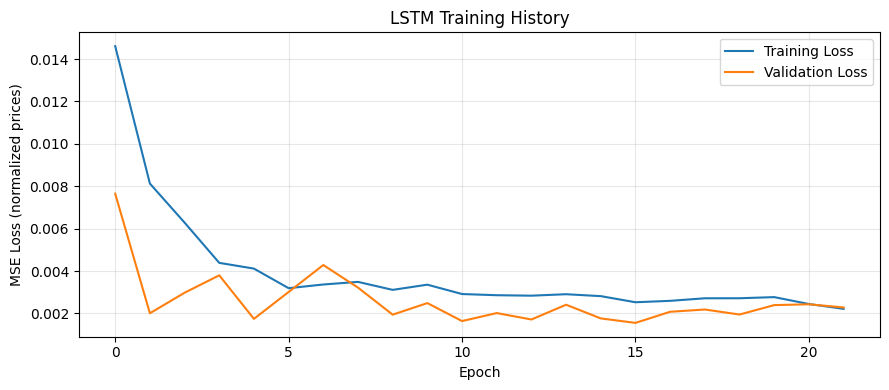

In [8]:

# Task 5: Actual vs predicted prices on unseen test data

test_dates = pd.to_datetime(dates[split_idx:])

plt.figure(figsize=(14, 6))
plt.plot(
    test_dates, y_test_actual,
    label="Actual Closing Price", linewidth=2
)
plt.plot(
    test_dates, y_pred_actual,
    label="LSTM Predicted Price", linewidth=1.5
)

plt.title("Actual vs Predicted Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Training and validation loss
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (normalized prices)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:

# Compare actual and predicted prices for unseen test records

results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Close": y_test_actual,
    "Predicted_Close": y_pred_actual
})

results["Absolute_Error"] = np.abs(
    results["Actual_Close"] - results["Predicted_Close"]
)

print("First 10 test predictions:")
display(results.head(10).round(2))

# Save all test predictions for your project
results.to_csv(
    "/content/stock_test_predictions.csv",
    index=False
)

print("Saved: stock_test_predictions.csv")


First 10 test predictions:


,Date,Actual_Close,Predicted_Close,Absolute_Error
0,2019-09-20,1254.349976,1187.530029,66.820000
1,2019-09-23,1239.199951,1199.560059,39.639999
2,2019-09-24,1278.699951,1206.790039,71.910004
3,2019-09-25,1279.550049,1223.000000,56.549999
4,2019-09-26,1296.800049,1237.180054,59.619999
5,2019-09-27,1309.050049,1253.319946,55.730000
6,2019-09-30,1332.250000,1269.619995,62.630001
7,2019-10-01,1304.900024,1288.560059,16.340000
8,2019-10-03,1311.050049,1296.939941,14.110000
9,2019-10-04,1308.099976,1304.310059,3.790000


Saved: stock_test_predictions.csv


In [10]:

# Forecast the next trading day's closing price

last_60_prices = scaled_prices[-LOOKBACK:].reshape(
    1, LOOKBACK, 1
)

next_scaled = model.predict(last_60_prices, verbose=0)

next_close = scaler.inverse_transform(
    next_scaled
)[0, 0]

last_date = pd.Timestamp(df["Date"].iloc[-1])

print("Stock:", STOCK_FILE.replace(".csv", ""))
print("Last available date:", last_date.date())
print(f"Last observed closing price: {prices[-1, 0]:.2f}")
print(f"Forecast next trading-day close: {next_close:.2f}")

print(
    "\nThis is a model-based estimate, not a guaranteed market price."
)


Stock: RELIANCE
Last available date: 2021-04-30
Last observed closing price: 1994.50
Forecast next trading-day close: 1943.65

This is a model-based estimate, not a guaranteed market price.


Directional Accuracy: 50.75%

Confusion Matrix:
[[153  37]
 [160  50]]


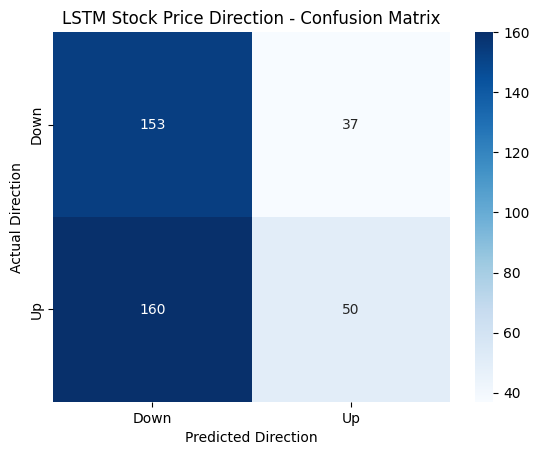


Classification Report:
              precision    recall  f1-score   support

        Down       0.49      0.81      0.61       190
          Up       0.57      0.24      0.34       210

    accuracy                           0.51       400
   macro avg       0.53      0.52      0.47       400
weighted avg       0.53      0.51      0.47       400



In [11]:

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Use the actual and predicted prices from your existing model
# Rename these two variables if your notebook uses different names.
actual_prices = np.array(y_test_actual).reshape(-1)
predicted_prices = np.array(y_pred_actual).reshape(-1)

# Previous day's actual closing price for each test day
previous_prices = np.array(prices[split_idx - 1:-1]).reshape(-1)

# Convert prices into direction classes:
# 1 = price went UP
# 0 = price went DOWN or remained unchanged
actual_direction = (actual_prices > previous_prices).astype(int)
predicted_direction = (predicted_prices > previous_prices).astype(int)

# Calculate accuracy
accuracy = accuracy_score(actual_direction, predicted_direction)
print(f"Directional Accuracy: {accuracy * 100:.2f}%")

# Generate confusion matrix
cm = confusion_matrix(
    actual_direction,
    predicted_direction,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Down", "Up"],
    yticklabels=["Down", "Up"]
)

plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")
plt.title("LSTM Stock Price Direction - Confusion Matrix")
plt.show()

print("\nClassification Report:")
print(classification_report(
    actual_direction,
    predicted_direction,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))
